<a href="https://colab.research.google.com/github/Mihret4204/pytorch-deep-learning/blob/main/01_Pytorch_workfow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PyTorch WorkFlow
🔗 Code: https://github.com/mrdbourke/pytorch-...

🔗 Ask a question: https://github.com/mrdbourke/pytorch-...

🔗 Course materials online: https://learnpytorch.io

🔗 Full course on Zero to Mastery (20+ hours more video): https://dbourke.link/ZTMPyTorch


what_were_covering = {
  
    1: "data (prepare and load)",

    2: "build model",

    3: "fitting the model to data (training)",

    4: "making predictions and evaluating a model (inference)",

    5: "saving and loading a model",
    
    6: "putting it all together"
}

Machine learning is a game of two parts:

Turn your data, whatever it is, into numbers (a representation).
Pick or build a model to learn the representation as best as possible.

# 1. Data Preparation

In [ ]:
import torch
from torch import nn
# nn contains all of PyTorch's building blocks for neural networks
import matplotlib.pyplot as plt

# Check PyTorch version
torch.__version__

'2.11.0+cpu'

In [ ]:
weight = 0.7
bias = 0.3

# y = ax + b

start = 0
end = 1
step = 0.02

X = torch.arange(start,end,step).unsqueeze(dim=1)
y = weight* X + bias

X[:10],y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

#Splitting data

Data Sets
* training set
* validation set (often but not always)
* Testing set

In [ ]:
train_split=int(0.8 * len(X))

X_train ,y_train = X[:train_split],y[:train_split]
X_test , y_test = X[train_split:],y[train_split:]
len(X_train),len(X_test),len(y_train),len(y_test)

(40, 10, 40, 10)

In [ ]:
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):

  plt.figure(figsize=(10, 7))


  plt.scatter(train_data, train_labels, c="b", s=4, label="Training data")


  plt.scatter(test_data, test_labels, c="g", s=4, label="Testing data")

  if predictions is not None:
    plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

  plt.legend(prop={"size": 14});

• train_data: The data points for the horizontal x-axis (typically your features or inputs).

• train_labels: The data points for the vertical y-axis (typically your target values or labels).
• c="b": Sets the color of the data points to blue ("b").

• s=4: Sets the size of the marker points to 4. A small size like this helps prevent overlapping when plotting a large number of data points.

• label="Training data": Assigns a label to this specific dataset. This text will appear in the chart's legend if you call plt.legend() later in your code.

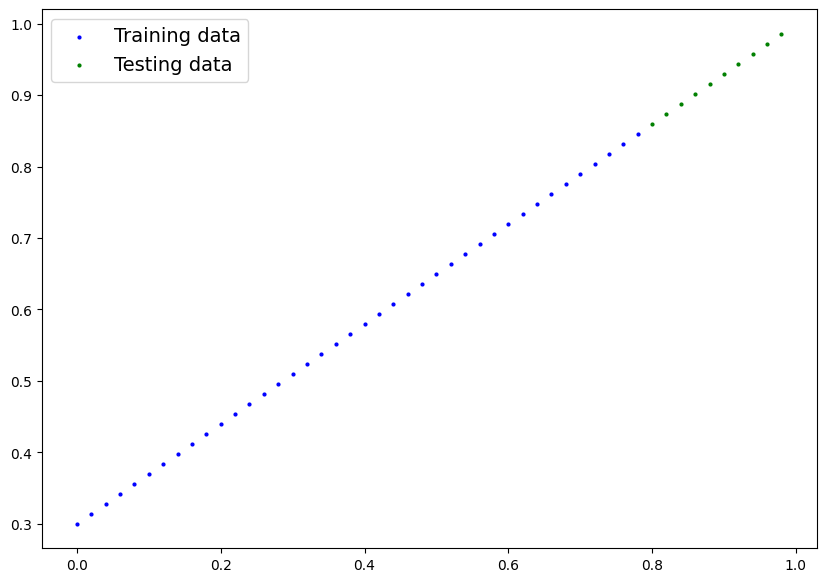

In [ ]:
plot_predictions()

# 2.Build a MOdel

In [ ]:
class LinearRegressionModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.weight = nn.Parameter(torch.randn(1,
                                           requires_grad=True,
                                           dtype=torch.float))
    self.bias = nn.Parameter(torch.randn(1,
                                           requires_grad=True,
                                           dtype=torch.float))

  def forward(self, x: torch.Tensor)-> torch.Tensor:
      return self.weight * x + self.bias

* nn.Module contains the larger building blocks (layers)

* nn.Parameter contains the smaller parameters like weights and biases (put these together to make nn.Module(s))

* forward() tells the larger blocks how to make calculations on inputs (tensors full of data) within nn.Module(s)
we need to rewrite forward()

* torch.optim contains optimization methods on how to improve the parameters within nn.Parameter to better represent input data

* pretrained modelin torchVision.models
* to evaluate torch.metrix
* torch.util.tensorboard to train though experimentation
* to check model parameters we use .parameters()

In [ ]:
from typing_extensions import List
torch.manual_seed(42)

model_0 = LinearRegressionModel()

list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [ ]:
model_0.state_dict()

OrderedDict([('weight', tensor([0.3367])), ('bias', tensor([0.1288]))])

In [ ]:
weight, bias

(0.7, 0.3)

In [ ]:
# TO check models predictive power
# when we pass data to our model it will pass through forward method

In [ ]:
X_test, y_test

(tensor([[0.8000],
         [0.8200],
         [0.8400],
         [0.8600],
         [0.8800],
         [0.9000],
         [0.9200],
         [0.9400],
         [0.9600],
         [0.9800]]),
 tensor([[0.8600],
         [0.8740],
         [0.8880],
         [0.9020],
         [0.9160],
         [0.9300],
         [0.9440],
         [0.9580],
         [0.9720],
         [0.9860]]))

In [35]:
with torch.inference_mode():
  y_preds = model_0(X_test)

# we can do similar to no_grad() but inference_mode is better

# with torch.no_grad():
#   y_preds = model_0(X_test)
y_preds

tensor([[0.8685],
        [0.8825],
        [0.8965],
        [0.9105],
        [0.9245],
        [0.9384],
        [0.9524],
        [0.9664],
        [0.9804],
        [0.9944]])

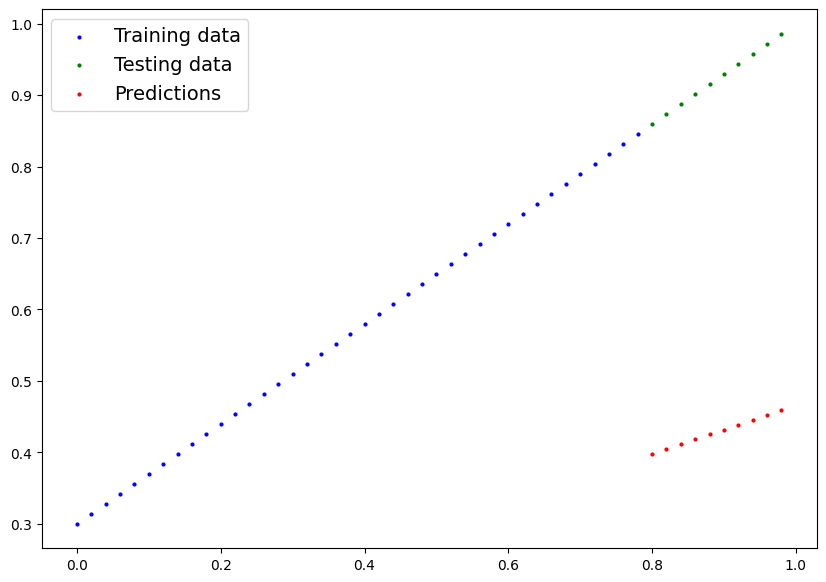

In [ ]:
plot_predictions(predictions=y_preds)

Loss function: **Measures** how wrong your model's predictions (e.g. y_preds) are compared to the truth labels (e.g. y_test). Lower the better.

Optimizer take account of a model and **adjust** the models parameter (i.e weight and bias).
  - lr rate to update the parameters at,
  - params parameter we wanna optimize
; parameter is value model set itself

In [ ]:
# setup a loss function
loss_fn = nn.L1Loss()

# setuup optimizer
# Stochastic means involving or characterized by a random variable, chance, or probability

optimizer = torch.optim.SGD(params=model_0.parameters(),
                            lr=0.01) #lr - learning   rate

In [ ]:
loss_fn

L1Loss()

IN training we will
loop through data

forward path mean move from input to output
calculate loss - compare forward pass adn truth labels

optimizer zero grad

loss backward - move backwards through network to calculate radient if each parameters with respect to the loss

optimizer step - use optimizer to adjust our model parameters to try and improve loss

Two loop

-training

-testing


### Build training and testing loop

loop data - > forward pass -> calculate loss -> optimizer - > loss backward -> optimizer

In [ ]:
list(model_0.eval().parameters())


[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [ ]:
list(model_0.parameters())

[Parameter containing:
 tensor([0.3367], requires_grad=True),
 Parameter containing:
 tensor([0.1288], requires_grad=True)]

In [ ]:
torch.manual_seed(42)
epochs = 200
# epoch is one loop through the data

epoch_count = []
loss_values = []
test_loss_values = []

for epoch in range(epochs):
  model_0.train()
  # training mode sets all parameters req ggradients to req gradients

  # 1. forward pass
  y_preds = model_0(X_train)

  # 2. loss fun
  loss = loss_fn(y_preds,y_train)
  print(loss)

  # 3. optimier zero grad
  optimizer.zero_grad()

  # 4. backpropagation
  loss.backward()

  # 5. step of optimizer
  optimizer.step()   #j

  model_0.eval() # turn off d/t settings that are not needed for testing/evaluation
  with torch.inference_mode():

    # 1. Forward pass on test data
    test_pred = model_0(X_test)

    # 2. Caculate loss on test data
    test_loss = loss_fn(test_pred, y_test.type(torch.float)) # predictions come in torch.float datatype, so comparisons need to be done with tensors of the same type

    # Print out what's happening
    if epoch % 10 == 0:
      epoch_count.append(epoch)
      loss_values.append(loss)
      test_loss_values.append(test_loss)

      print(f"Epoch: {epoch} | MAE Train Loss: {loss} | MAE Test Loss: {test_loss} ")
print(model_0.state_dict())

tensor(0.3129, grad_fn=<MeanBackward0>)
Epoch: 0 | MAE Train Loss: 0.31288138031959534 | MAE Test Loss: 0.48106518387794495 
tensor(0.3014, grad_fn=<MeanBackward0>)
tensor(0.2898, grad_fn=<MeanBackward0>)
tensor(0.2783, grad_fn=<MeanBackward0>)
tensor(0.2668, grad_fn=<MeanBackward0>)
tensor(0.2553, grad_fn=<MeanBackward0>)
tensor(0.2438, grad_fn=<MeanBackward0>)
tensor(0.2322, grad_fn=<MeanBackward0>)
tensor(0.2207, grad_fn=<MeanBackward0>)
tensor(0.2092, grad_fn=<MeanBackward0>)
tensor(0.1977, grad_fn=<MeanBackward0>)
Epoch: 10 | MAE Train Loss: 0.1976713240146637 | MAE Test Loss: 0.3463551998138428 
tensor(0.1862, grad_fn=<MeanBackward0>)
tensor(0.1746, grad_fn=<MeanBackward0>)
tensor(0.1631, grad_fn=<MeanBackward0>)
tensor(0.1516, grad_fn=<MeanBackward0>)
tensor(0.1401, grad_fn=<MeanBackward0>)
tensor(0.1285, grad_fn=<MeanBackward0>)
tensor(0.1170, grad_fn=<MeanBackward0>)
tensor(0.1061, grad_fn=<MeanBackward0>)
tensor(0.0968, grad_fn=<MeanBackward0>)
tensor(0.0891, grad_fn=<MeanBac

In [ ]:
import numpy as np
np.array(torch.tensor(loss_values).cpu().numpy()), test_loss_values

/tmp/ipykernel_17801/1761919367.py:2: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  np.array(torch.tensor(loss_values).cpu().numpy()), test_loss_values


(array([0.31288138, 0.19767132, 0.08908726, 0.05314853, 0.04543797,
        0.04167863, 0.03818933, 0.0347609 , 0.03132383, 0.0278874 ,
        0.02445896, 0.02102021, 0.01758547, 0.01415539, 0.01071659,
        0.00728353, 0.00385178, 0.00893248, 0.00893248, 0.00893248],
       dtype=float32),
 [tensor(0.4811),
  tensor(0.3464),
  tensor(0.2173),
  tensor(0.1446),
  tensor(0.1136),
  tensor(0.0992),
  tensor(0.0889),
  tensor(0.0806),
  tensor(0.0723),
  tensor(0.0647),
  tensor(0.0565),
  tensor(0.0482),
  tensor(0.0406),
  tensor(0.0323),
  tensor(0.0241),
  tensor(0.0165),
  tensor(0.0082),
  tensor(0.0050),
  tensor(0.0050),
  tensor(0.0050)])

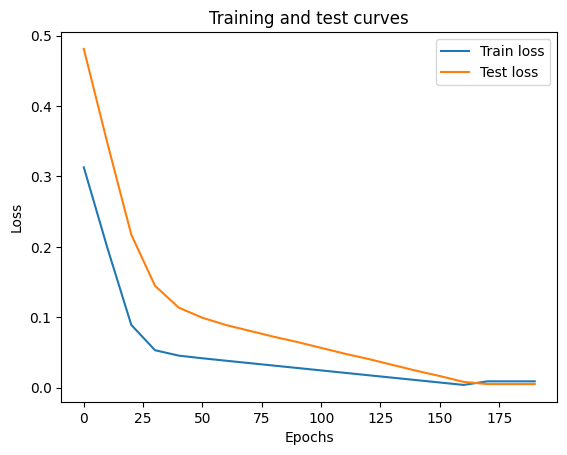

In [ ]:
plt.plot(epoch_count,np.array(torch.tensor(loss_values).cpu().numpy()), label="Train loss")
plt.plot(epoch_count, test_loss_values, label="Test loss")
plt.title("Training and test curves")
plt.ylabel("Loss")
plt.xlabel("Epochs")
plt.legend();

In [ ]:
with torch.inference_mode():
  y_preds_new = model_0(X_test)

In [ ]:
model_0.state_dict()

OrderedDict([('weight', tensor([0.6990])), ('bias', tensor([0.3093]))])

### After it learn prediction 200

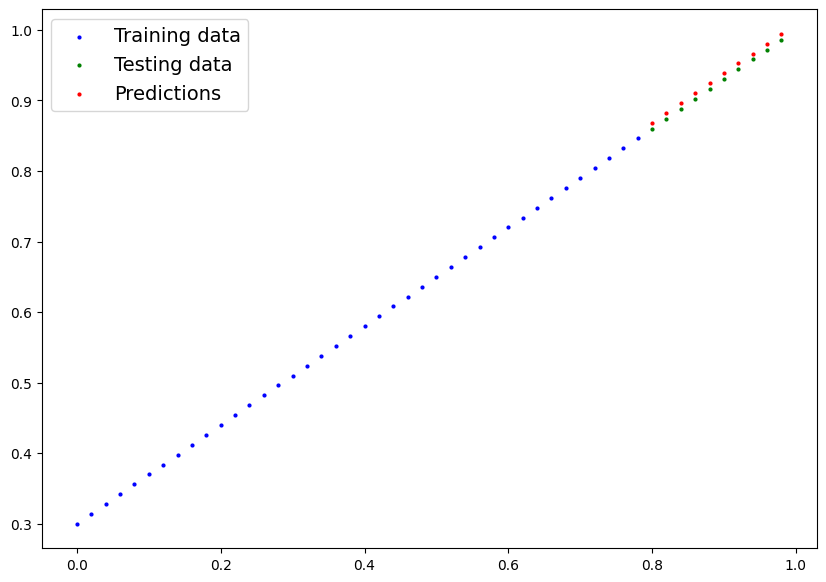

In [ ]:
plot_predictions(predictions=y_preds_new)

### Saving a model in Pyoch

There are three ways:
1. trorch.save():- to save PyThorch ojec in pyhone pickle format

2. torch.load():- allow to load saved obj

3. torch.nnModule.load_state_dict():- allow to load model save state dictionary.

In [ ]:
from pathlib import Path
MODEL_PATH = Path("MODELS")
MODEL_PATH.mkdir(parents=True, exist_ok=True)
MODEL_NAME = "01_Pytorch_workfow_model_0.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME
MODEL_SAVE_PATH
torch.save(obj=model_0.state_dict(),
           f=MODEL_SAVE_PATH)


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [30]:
## loading model

model_0.state_dict()

OrderedDict([('weight', tensor([0.6990])), ('bias', tensor([0.3093]))])

In [29]:
# To loas a save d stated_dict we instantiate new instance of our model class

loaded_model_0 = LinearRegressionModel()

# Load the saved state did
loaded_model_0.load_state_dict(torch.load(f=MODEL_SAVE_PATH))


<All keys matched successfully>

In [31]:
loaded_model_0.state_dict()

OrderedDict([('weight', tensor([0.6990])), ('bias', tensor([0.3093]))])

In [36]:
## Make some prediction in our loaded model

loaded_model_0.eval()

with torch.inference_mode():
  loaded_model_preds = loaded_model_0(X_test)

loaded_model_preds

tensor([[0.8685],
        [0.8825],
        [0.8965],
        [0.9105],
        [0.9245],
        [0.9384],
        [0.9524],
        [0.9664],
        [0.9804],
        [0.9944]])

In [37]:
y_preds == loaded_model_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])

In [38]:
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.__version__

'2.11.0+cpu'

device-aggnostic code ; if it get access to GPU our code will use it.

In [40]:
device = "cuda" if torch.cuda.is_available() else 'cpu'

print(f"Using device {device}")

Using device cpu


### Data

In [41]:
weight = 0.7
bias = 0.3

start = 0
end = 1
step = 0.02

X= torch.arange(start,end,step).unsqueeze(dim=1)
y = weight*X + bias
X[:10],y[:10]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800],
         [0.1000],
         [0.1200],
         [0.1400],
         [0.1600],
         [0.1800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560],
         [0.3700],
         [0.3840],
         [0.3980],
         [0.4120],
         [0.4260]]))

In [42]:
train_split = int(0.8*len(X))
X_train,y_train = X[:train_split],y[:train_split]
X_test,y_test = X[train_split:],y[train_split:]
len(X_train), len(y_train), len(X_test),len(y_test)

(40, 40, 10, 10)

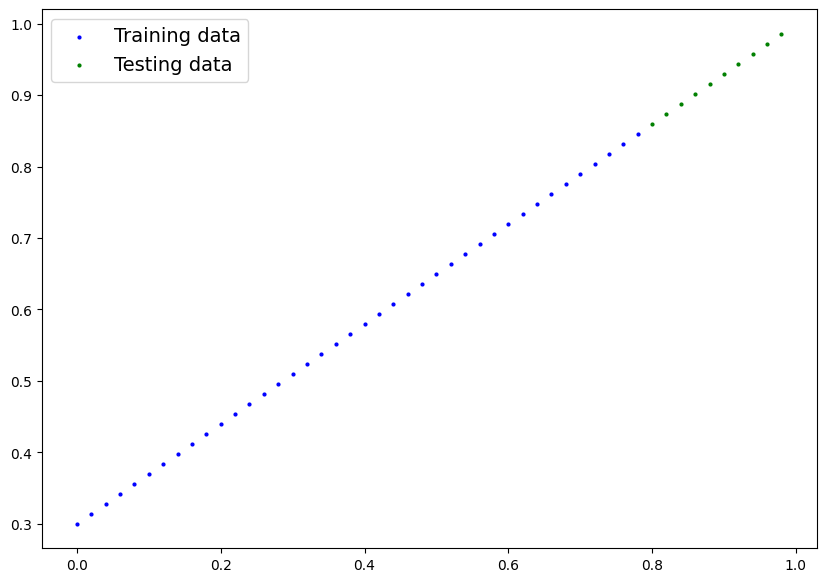

In [43]:
plot_predictions(X_train,y_train,X_test,y_test)

In [44]:
class LinearRegressionModelV2(nn.Module):
    def __init__(self):
        super().__init__()
        # Use nn.Linear() for creating the model parameters
        self.linear_layer = nn.Linear(in_features=1,
                                      out_features=1)

    # Define the forward computation (input data x flows through nn.Linear())
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.linear_layer(x)

# Set the manual seed when creating the model (this isn't always needed but is used for demonstrative purposes, try commenting it out and seeing what happens)
torch.manual_seed(42)
model_1 = LinearRegressionModelV2()
model_1, model_1.state_dict()


(LinearRegressionModelV2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [45]:
model_1.state_dict()

OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
             ('linear_layer.bias', tensor([0.8300]))])

In [46]:
X_train[:5], y_train[:5]

(tensor([[0.0000],
         [0.0200],
         [0.0400],
         [0.0600],
         [0.0800]]),
 tensor([[0.3000],
         [0.3140],
         [0.3280],
         [0.3420],
         [0.3560]]))

In [47]:
device

'cpu'

In [48]:
model_1.to(device)
next(model_1.parameters()).device

device(type='cpu')

In [51]:
from ast import Param
loss_fn = nn.L1Loss()

optimizer = torch.optim.SGD(
    params=model_1.parameters(),
    lr=0.01
)

In [52]:
torch.manual_seed(42)

epochs = 200

for epoch in range(epochs):
  model_1.train()

  y_preds = model_1(X_train)

  loss = loss_fn(y_preds, y_train)

  optimizer.zero_grad()

  loss.backward()

  optimizer.step()

  model_1.eval()

  with torch.inference_mode():
    text_pred = model_1(X_test)

    test_loss = loss_fn(test_pred, y_test)

    if epoch % 10 == 0:
      print(f"Epoch: {epoch} | Train loss: {loss} | Test loss: {test_loss}")

Epoch: 0 | Train loss: 0.5551779866218567 | Test loss: 0.008447891101241112
Epoch: 10 | Train loss: 0.4399680495262146 | Test loss: 0.008447891101241112
Epoch: 20 | Train loss: 0.3247582018375397 | Test loss: 0.008447891101241112
Epoch: 30 | Train loss: 0.20954827964305878 | Test loss: 0.008447891101241112
Epoch: 40 | Train loss: 0.09433844685554504 | Test loss: 0.008447891101241112
Epoch: 50 | Train loss: 0.023886386305093765 | Test loss: 0.008447891101241112
Epoch: 60 | Train loss: 0.0199567973613739 | Test loss: 0.008447891101241112
Epoch: 70 | Train loss: 0.016517987474799156 | Test loss: 0.008447891101241112
Epoch: 80 | Train loss: 0.013089170679450035 | Test loss: 0.008447891101241112
Epoch: 90 | Train loss: 0.009653178043663502 | Test loss: 0.008447891101241112
Epoch: 100 | Train loss: 0.006215679459273815 | Test loss: 0.008447891101241112
Epoch: 110 | Train loss: 0.002787243574857712 | Test loss: 0.008447891101241112
Epoch: 120 | Train loss: 0.0012645035749301314 | Test loss: 0

In [53]:
# Turn model into evaluation mode
model_1.eval()

# Make predictions on the test data
with torch.inference_mode():
    y_preds = model_1(X_test)
y_preds

tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]])

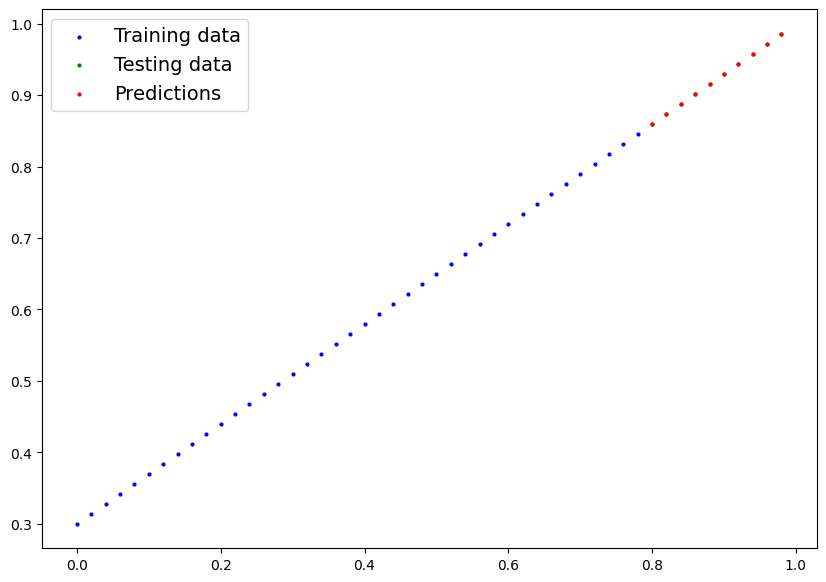

In [54]:
plot_predictions(predictions=y_preds.cpu())

In [55]:
from pathlib import Path


MODEL_PATH = Path("models")
MODEL_PATH.mkdir(parents=True, exist_ok=True)

# 2. Create model save path
MODEL_NAME = "01_pytorch_workflow_model_1.pth"
MODEL_SAVE_PATH = MODEL_PATH / MODEL_NAME

# 3. Save the model state dict
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model_1.state_dict(),
           f=MODEL_SAVE_PATH)

Saving model to: models/01_pytorch_workflow_model_1.pth


In [ ]:
model_1.state_dict()

In [56]:
loaded_model_1 = LinearRegressionModelV2()


loaded_model_1.load_state_dict(torch.load(MODEL_SAVE_PATH))


loaded_model_1.to(device)

print(f"Loaded model:\n{loaded_model_1}")
print(f"Model on device:\n{next(loaded_model_1.parameters()).device}")

Loaded model:
LinearRegressionModelV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)
Model on device:
cpu


In [57]:

loaded_model_1.eval()
with torch.inference_mode():
    loaded_model_1_preds = loaded_model_1(X_test)
y_preds == loaded_model_1_preds

tensor([[True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True],
        [True]])